In [1]:
import pandas as pd


In [2]:
players = pd.read_csv(
    "cleaned_data/player_appearances_cleaned_v4.csv",
    low_memory=False
)
players.shape

(108681, 24)

In [3]:
group_cols = ["season", "fixture", "team_name_corrected"]

group_sizes = players.groupby(group_cols).size()

print("Number of team-fixture groups:", len(group_sizes))
print("\nPlayers per team-fixture:")
print(group_sizes.describe())

Number of team-fixture groups: 7600

Players per team-fixture:
count    7600.000000
mean       14.300132
std         1.027609
min        11.000000
25%        14.000000
50%        14.000000
75%        15.000000
max        17.000000
dtype: float64


In [4]:
first_group = players.groupby(group_cols).get_group(
    tuple(players[group_cols].iloc[0])
)

first_group[
    ["season", "fixture", "team_name_corrected",
     "element", "name", "position", "minutes", "result"]
]

,season,fixture,team_name_corrected,element,name,position,minutes,result
0,2016-17,3,Everton,142,Aaron_Lennon,Midfielder,15,D
31,2016-17,3,Everton,144,Arouna_Koné,Forward,23,D
97,2016-17,3,Everton,137,Gareth_Barry,Midfielder,84,D
105,2016-17,3,Everton,141,Gerard_Deulofeu,Midfielder,67,D
118,2016-17,3,Everton,488,Idrissa_Gueye,Midfielder,90,D
124,2016-17,3,Everton,136,James_McCarthy,Midfielder,90,D
154,2016-17,3,Everton,133,Kevin_Mirallas,Midfielder,75,D
159,2016-17,3,Everton,125,Leighton_Baines,Defender,90,D
170,2016-17,3,Everton,124,Maarten_Stekelenburg,Goalkeeper,90,D
178,2016-17,3,Everton,495,Mason_Holgate,Defender,90,D


Create player pairs for testing-- tuples

In [5]:
from itertools import combinations

player_ids = first_group["element"].tolist()

pairs = list(combinations(player_ids, 2))

print("Number of players:", len(player_ids))
print("Number of pairs:", len(pairs))
print("\nFirst 10 pairs:")
print(pairs[:10])

Number of players: 14
Number of pairs: 91

First 10 pairs:
[(142, 144), (142, 137), (142, 141), (142, 488), (142, 136), (142, 133), (142, 125), (142, 124), (142, 495), (142, 127)]


Create dataframe 

In [6]:
pairs_df = pd.DataFrame(
    pairs,
    columns=["player_1", "player_2"]
)

pairs_df.head(10)

,player_1,player_2
0,142,144
1,142,137
2,142,141
3,142,488
4,142,136
5,142,133
6,142,125
7,142,124
8,142,495
9,142,127


In [7]:
pairs_df["season"] = first_group["season"].iloc[0]
pairs_df["fixture"] = first_group["fixture"].iloc[0]
pairs_df["team"] = first_group["team_name_corrected"].iloc[0]
pairs_df["result"] = first_group["result"].iloc[0]

pairs_df.head(10)

,player_1,player_2,season,fixture,team,result
0,142,144,2016-17,3,Everton,D
1,142,137,2016-17,3,Everton,D
2,142,141,2016-17,3,Everton,D
3,142,488,2016-17,3,Everton,D
4,142,136,2016-17,3,Everton,D
5,142,133,2016-17,3,Everton,D
6,142,125,2016-17,3,Everton,D
7,142,124,2016-17,3,Everton,D
8,142,495,2016-17,3,Everton,D
9,142,127,2016-17,3,Everton,D


Put tuples in ascending order to standarize values of alternating elements-- always (lower, higher) tuple

In [8]:
pairs_df[["player_1", "player_2"]] = pd.DataFrame(
    [sorted(pair) for pair in pairs_df[["player_1", "player_2"]].itertuples(index=False, name=None)],
    index=pairs_df.index
)

pairs_df.head(10)

,player_1,player_2,season,fixture,team,result
0,142,144,2016-17,3,Everton,D
1,137,142,2016-17,3,Everton,D
2,141,142,2016-17,3,Everton,D
3,142,488,2016-17,3,Everton,D
4,136,142,2016-17,3,Everton,D
5,133,142,2016-17,3,Everton,D
6,125,142,2016-17,3,Everton,D
7,124,142,2016-17,3,Everton,D
8,142,495,2016-17,3,Everton,D
9,127,142,2016-17,3,Everton,D


In [9]:
print("Total pairs:", len(pairs_df))

print("Duplicate pairs:",
      pairs_df.duplicated(
          subset=["player_1", "player_2"]
      ).sum())

print("Incorrectly ordered pairs:",
      (pairs_df["player_1"] >= pairs_df["player_2"]).sum())

Total pairs: 91
Duplicate pairs: 0
Incorrectly ordered pairs: 0


In [10]:
for group_key, group in players.groupby(group_cols):

    print("Group:", group_key)
    print("Number of players:", len(group))
    print("Result:", group["result"].iloc[0])
    print()

    break

Group: ('2016-17', 1, 'Burnley')
Number of players: 13
Result: L



Generate Pairs Inside the Loop

In [11]:
for group_key, group in players.groupby(group_cols):

    player_ids = sorted(group["element"].tolist())

    group_pairs = list(combinations(player_ids, 2))

    print("Group:", group_key)
    print("Players:", len(player_ids))
    print("Pairs generated:", len(group_pairs))
    print("First 10 pairs:", group_pairs[:10])

    break

Group: ('2016-17', 1, 'Burnley')
Players: 13
Pairs generated: 78
First 10 pairs: [(54, 55), (54, 56), (54, 57), (54, 58), (54, 61), (54, 62), (54, 63), (54, 64), (54, 67), (54, 68)]


Collect pairs from all 7600 groups-- nested loops

In [12]:
all_pairs = []

for group_key, group in players.groupby(group_cols):

    season, fixture, team = group_key
    result = group["result"].iloc[0]

    player_ids = sorted(group["element"].tolist())

    for player_1, player_2 in combinations(player_ids, 2):
        all_pairs.append(
            (season, fixture, team, player_1, player_2, result)
        )

    #if len(all_pairs) >= 250:
    #    break

print("Pairs collected:", len(all_pairs))
print("First 5 records:")
print(all_pairs[:5])

Pairs collected: 726748
First 5 records:
[('2016-17', 1, 'Burnley', 54, 55, 'L'), ('2016-17', 1, 'Burnley', 54, 56, 'L'), ('2016-17', 1, 'Burnley', 54, 57, 'L'), ('2016-17', 1, 'Burnley', 54, 58, 'L'), ('2016-17', 1, 'Burnley', 54, 61, 'L')]


Convert complete list into dataframe

In [13]:
all_pairs_df = pd.DataFrame(
    all_pairs,
    columns=[
        "season",
        "fixture",
        "team",
        "player_1",
        "player_2",
        "result"
    ]
)

print("Dataset shape:", all_pairs_df.shape)

all_pairs_df.head(10)

Dataset shape: (726748, 6)


,season,fixture,team,player_1,player_2,result
0,2016-17,1,Burnley,54,55,L
1,2016-17,1,Burnley,54,56,L
2,2016-17,1,Burnley,54,57,L
3,2016-17,1,Burnley,54,58,L
4,2016-17,1,Burnley,54,61,L
5,2016-17,1,Burnley,54,62,L
6,2016-17,1,Burnley,54,63,L
7,2016-17,1,Burnley,54,64,L
8,2016-17,1,Burnley,54,67,L
9,2016-17,1,Burnley,54,68,L


Check math

In [14]:
expected_pairs = (
    group_sizes * (group_sizes - 1) // 2
).sum()

actual_pairs = len(all_pairs_df)

print("Expected pairs:", expected_pairs)
print("Actual pairs:", actual_pairs)
print("Difference:", actual_pairs - expected_pairs)

Expected pairs: 726748
Actual pairs: 726748
Difference: 0


Check for duplicates and ordering errors

In [15]:
duplicate_pairs = all_pairs_df.duplicated(
    subset=[
        "season",
        "fixture",
        "team",
        "player_1",
        "player_2"
    ]
).sum()

incorrect_order = (
    all_pairs_df["player_1"] >= all_pairs_df["player_2"]
).sum()

missing_values = all_pairs_df.isnull().sum()

print("Duplicate pair appearances:", duplicate_pairs)
print("Incorrectly ordered pairs:", incorrect_order)
print("\nMissing values:")
print(missing_values)

Duplicate pair appearances: 0
Incorrectly ordered pairs: 0

Missing values:
season      0
fixture     0
team        0
player_1    0
player_2    0
result      0
dtype: int64


Save player pair dataset in csv and excel

In [16]:
all_pairs_df.to_csv(
    "cleaned_data/player_pairs_v1.csv",
    index=False
)

print("Player-pair dataset saved.")

Player-pair dataset saved.


In [17]:
all_pairs_df.to_excel(
    "cleaned_data/player_pairs_v1.xlsx",
    index=False,
    sheet_name="Player Pairs"
)

print("Excel file saved successfully.")

Excel file saved successfully.


Aggregate player pairs, matches, wins, draws, loses

In [18]:
pair_group_cols = [
    "season",
    "team",
    "player_1",
    "player_2"
]

In [19]:
pair_stats = (
    all_pairs_df.groupby(pair_group_cols)
    .agg(
        matches_together=("result", "size"),
        wins=("result", lambda x: (x == "W").sum()),
        draws=("result", lambda x: (x == "D").sum()),
        losses=("result", lambda x: (x == "L").sum())
    )
    .reset_index()
)

print("Unique pair-season-team combinations:", len(pair_stats))

pair_stats.head(10)

Unique pair-season-team combinations: 63320


,season,team,player_1,player_2,matches_together,wins,draws,losses
0,2016-17,Arsenal,1,2,1,0,0,1
1,2016-17,Arsenal,1,3,2,0,1,1
2,2016-17,Arsenal,1,5,1,0,1,0
3,2016-17,Arsenal,1,6,2,0,1,1
4,2016-17,Arsenal,1,10,2,0,1,1
5,2016-17,Arsenal,1,12,2,0,1,1
6,2016-17,Arsenal,1,13,2,0,1,1
7,2016-17,Arsenal,1,14,1,0,1,0
8,2016-17,Arsenal,1,16,1,0,0,1
9,2016-17,Arsenal,1,18,1,0,0,1


Validate Aggregation-- total=wins+loses+draws 

In [20]:
result_total = (
    pair_stats["wins"] +
    pair_stats["draws"] +
    pair_stats["losses"]
)

invalid_rows = (
    result_total != pair_stats["matches_together"]
).sum()

total_appearances = pair_stats["matches_together"].sum()

print("Invalid pair records:", invalid_rows)
print("Original pair appearances:", len(all_pairs_df))
print("Aggregated pair appearances:", total_appearances)
print("Difference:", total_appearances - len(all_pairs_df))

Invalid pair records: 0
Original pair appearances: 726748
Aggregated pair appearances: 726748
Difference: 0


Calculate pair performance-- points per game, win rate/ add columns

In [21]:
pair_stats["win_pct"] = (
    pair_stats["wins"] /
    pair_stats["matches_together"] * 100
).round(2)

pair_stats["points_per_match"] = (
    (pair_stats["wins"] * 3 + pair_stats["draws"]) /
    pair_stats["matches_together"]
).round(2)

pair_stats.head(10)

,season,team,player_1,player_2,matches_together,wins,draws,losses,win_pct,points_per_match
0,2016-17,Arsenal,1,2,1,0,0,1,0.0,0.0
1,2016-17,Arsenal,1,3,2,0,1,1,0.0,0.5
2,2016-17,Arsenal,1,5,1,0,1,0,0.0,1.0
3,2016-17,Arsenal,1,6,2,0,1,1,0.0,0.5
4,2016-17,Arsenal,1,10,2,0,1,1,0.0,0.5
5,2016-17,Arsenal,1,12,2,0,1,1,0.0,0.5
6,2016-17,Arsenal,1,13,2,0,1,1,0.0,0.5
7,2016-17,Arsenal,1,14,1,0,1,0,0.0,1.0
8,2016-17,Arsenal,1,16,1,0,0,1,0.0,0.0
9,2016-17,Arsenal,1,18,1,0,0,1,0.0,0.0


Min pair appearance together of 10

In [22]:
qualified_pairs = pair_stats[
    pair_stats["matches_together"] >= 10
].copy()

print("Total combinations:", len(pair_stats))
print("Qualified combinations:", len(qualified_pairs))

print(
    "Percentage retained:",
    round(len(qualified_pairs) / len(pair_stats) * 100, 2)
)

qualified_pairs.head(10)

Total combinations: 63320
Qualified combinations: 30880
Percentage retained: 48.77


,season,team,player_1,player_2,matches_together,wins,draws,losses,win_pct,points_per_match
16,2016-17,Arsenal,2,3,32,20,5,7,62.50,2.03
18,2016-17,Arsenal,2,5,16,10,1,5,62.50,1.94
19,2016-17,Arsenal,2,6,30,19,4,7,63.33,2.03
20,2016-17,Arsenal,2,7,11,10,0,1,90.91,2.73
23,2016-17,Arsenal,2,10,33,20,5,8,60.61,1.97
25,2016-17,Arsenal,2,12,35,22,5,8,62.86,2.03
26,2016-17,Arsenal,2,13,25,13,4,8,52.00,1.72
27,2016-17,Arsenal,2,14,30,21,4,5,70.00,2.23
29,2016-17,Arsenal,2,16,21,14,3,4,66.67,2.14
31,2016-17,Arsenal,2,18,27,14,5,8,51.85,1.74


Sort player combinations

In [23]:
top_pairs = qualified_pairs.sort_values(
    by=["win_pct", "matches_together"],
    ascending=[False, False]
)

top_pairs.head(20)

,season,team,player_1,player_2,matches_together,wins,draws,losses,win_pct,points_per_match
20284,2019-20,Liverpool,181,200,20,20,0,0,100.0,3.0
20441,2019-20,Liverpool,191,200,19,19,0,0,100.0,3.0
15527,2018-19,Man City,264,271,15,15,0,0,100.0,3.0
15484,2018-19,Man City,260,279,14,14,0,0,100.0,3.0
15607,2018-19,Man City,270,279,13,13,0,0,100.0,3.0
15616,2018-19,Man City,271,279,13,13,0,0,100.0,3.0
15646,2018-19,Man City,276,279,13,13,0,0,100.0,3.0
32639,2021-22,Liverpool,221,225,13,13,0,0,100.0,3.0
47058,2023-24,Man City,365,566,13,13,0,0,100.0,3.0
15528,2018-19,Man City,264,272,12,12,0,0,100.0,3.0


Calculate team performance baseline

In [24]:
team_matches = players[
    ["season", "fixture", "team_name_corrected", "result"]
].drop_duplicates()

print("Total team-match records:", len(team_matches))

team_matches.head(10)

Total team-match records: 7600


,season,fixture,team_name_corrected,result
0,2016-17,3,Everton,D
1,2016-17,8,Arsenal,L
2,2016-17,4,Hull,W
4,2016-17,6,Middlesbrough,D
6,2016-17,8,Liverpool,W
7,2016-17,9,Bournemouth,L
8,2016-17,7,Watford,D
9,2016-17,5,Sunderland,L
10,2016-17,10,West Ham,L
12,2016-17,4,Leicester,L


Calculate team season baselines

In [25]:
team_baselines = (
    team_matches.groupby(["season", "team_name_corrected"])
    .agg(
        matches=("result", "size"),
        wins=("result", lambda x: (x == "W").sum()),
        draws=("result", lambda x: (x == "D").sum()),
        losses=("result", lambda x: (x == "L").sum())
    )
    .reset_index()
)

print("Team-season records:", len(team_baselines))

team_baselines.head(10)

Team-season records: 200


,season,team_name_corrected,matches,wins,draws,losses
0,2016-17,Arsenal,38,23,6,9
1,2016-17,Bournemouth,38,12,10,16
2,2016-17,Burnley,38,11,7,20
3,2016-17,Chelsea,38,30,3,5
4,2016-17,Crystal Palace,38,12,5,21
5,2016-17,Everton,38,17,10,11
6,2016-17,Hull,38,9,7,22
7,2016-17,Leicester,38,12,8,18
8,2016-17,Liverpool,38,22,10,6
9,2016-17,Man City,38,23,9,6


Calc team baseline performance-- season

In [26]:
team_baselines["team_win_pct"] = (
    team_baselines["wins"] /
    team_baselines["matches"] * 100
).round(2)

team_baselines["team_points_per_match"] = (
    (team_baselines["wins"] * 3 + team_baselines["draws"]) /
    team_baselines["matches"]
).round(2)

team_baselines.head(10)

,season,team_name_corrected,matches,wins,draws,losses,team_win_pct,team_points_per_match
0,2016-17,Arsenal,38,23,6,9,60.53,1.97
1,2016-17,Bournemouth,38,12,10,16,31.58,1.21
2,2016-17,Burnley,38,11,7,20,28.95,1.05
3,2016-17,Chelsea,38,30,3,5,78.95,2.45
4,2016-17,Crystal Palace,38,12,5,21,31.58,1.08
5,2016-17,Everton,38,17,10,11,44.74,1.61
6,2016-17,Hull,38,9,7,22,23.68,0.89
7,2016-17,Leicester,38,12,8,18,31.58,1.16
8,2016-17,Liverpool,38,22,10,6,57.89,2.00
9,2016-17,Man City,38,23,9,6,60.53,2.05


Merge team baselines with player contributions

In [27]:
pair_comparison = qualified_pairs.merge(
    team_baselines[
        ["season", "team_name_corrected",
         "team_win_pct", "team_points_per_match"]
    ],
    left_on=["season", "team"],
    right_on=["season", "team_name_corrected"],
    how="left",
    validate="many_to_one"
)

pair_comparison = pair_comparison.drop(
    columns=["team_name_corrected"]
)

print("Records after merge:", len(pair_comparison))

pair_comparison.head(10)

Records after merge: 30880


,season,team,player_1,player_2,matches_together,wins,draws,losses,win_pct,points_per_match,team_win_pct,team_points_per_match
0,2016-17,Arsenal,2,3,32,20,5,7,62.50,2.03,60.53,1.97
1,2016-17,Arsenal,2,5,16,10,1,5,62.50,1.94,60.53,1.97
2,2016-17,Arsenal,2,6,30,19,4,7,63.33,2.03,60.53,1.97
3,2016-17,Arsenal,2,7,11,10,0,1,90.91,2.73,60.53,1.97
4,2016-17,Arsenal,2,10,33,20,5,8,60.61,1.97,60.53,1.97
5,2016-17,Arsenal,2,12,35,22,5,8,62.86,2.03,60.53,1.97
6,2016-17,Arsenal,2,13,25,13,4,8,52.00,1.72,60.53,1.97
7,2016-17,Arsenal,2,14,30,21,4,5,70.00,2.23,60.53,1.97
8,2016-17,Arsenal,2,16,21,14,3,4,66.67,2.14,60.53,1.97
9,2016-17,Arsenal,2,18,27,14,5,8,51.85,1.74,60.53,1.97


In [28]:
print("Missing team win percentages:",
      pair_comparison["team_win_pct"].isnull().sum())

print("Missing team points per match:",
      pair_comparison["team_points_per_match"].isnull().sum())

Missing team win percentages: 0
Missing team points per match: 0


In [29]:
pair_comparison["win_pct_difference"] = (
    pair_comparison["win_pct"] -
    pair_comparison["team_win_pct"]
).round(2)

pair_comparison["points_difference"] = (
    pair_comparison["points_per_match"] -
    pair_comparison["team_points_per_match"]
).round(2)

pair_comparison.head(10)

,season,team,player_1,player_2,matches_together,wins,draws,losses,win_pct,points_per_match,team_win_pct,team_points_per_match,win_pct_difference,points_difference
0,2016-17,Arsenal,2,3,32,20,5,7,62.50,2.03,60.53,1.97,1.97,0.06
1,2016-17,Arsenal,2,5,16,10,1,5,62.50,1.94,60.53,1.97,1.97,-0.03
2,2016-17,Arsenal,2,6,30,19,4,7,63.33,2.03,60.53,1.97,2.80,0.06
3,2016-17,Arsenal,2,7,11,10,0,1,90.91,2.73,60.53,1.97,30.38,0.76
4,2016-17,Arsenal,2,10,33,20,5,8,60.61,1.97,60.53,1.97,0.08,0.00
5,2016-17,Arsenal,2,12,35,22,5,8,62.86,2.03,60.53,1.97,2.33,0.06
6,2016-17,Arsenal,2,13,25,13,4,8,52.00,1.72,60.53,1.97,-8.53,-0.25
7,2016-17,Arsenal,2,14,30,21,4,5,70.00,2.23,60.53,1.97,9.47,0.26
8,2016-17,Arsenal,2,16,21,14,3,4,66.67,2.14,60.53,1.97,6.14,0.17
9,2016-17,Arsenal,2,18,27,14,5,8,51.85,1.74,60.53,1.97,-8.68,-0.23


Identify strongest combinations

In [30]:
top_performing_pairs = pair_comparison.sort_values(
    by=["points_difference", "matches_together"],
    ascending=[False, False]
)

top_performing_pairs[
    [
        "season",
        "team",
        "player_1",
        "player_2",
        "matches_together",
        "points_per_match",
        "team_points_per_match",
        "points_difference"
    ]
].head(20)

,season,team,player_1,player_2,matches_together,points_per_match,team_points_per_match,points_difference
27115,2024-25,West Ham,517,591,12,2.33,1.13,1.20
20893,2023-24,Aston Villa,55,584,10,2.80,1.79,1.01
24661,2024-25,Brighton,113,147,10,2.60,1.61,0.99
16226,2021-22,Newcastle,291,697,11,2.27,1.29,0.98
11511,2020-21,Arsenal,17,23,12,2.58,1.61,0.97
11537,2020-21,Arsenal,23,526,12,2.58,1.61,0.97
14755,2021-22,Brighton,61,462,10,2.30,1.34,0.96
27114,2024-25,West Ham,517,588,12,2.08,1.13,0.95
16204,2021-22,Newcastle,109,291,13,2.23,1.29,0.94
3533,2017-18,Crystal Palace,117,221,11,2.09,1.16,0.93


Check against a 20 min games together

In [31]:
qualified_20 = pair_comparison[
    pair_comparison["matches_together"] >= 20
].copy()

top_20_pairs = qualified_20.sort_values(
    by=["points_difference", "matches_together"],
    ascending=[False, False]
)

print("Pairs with 10+ matches:", len(pair_comparison))
print("Pairs with 20+ matches:", len(qualified_20))

top_20_pairs[
    [
        "season",
        "team",
        "player_1",
        "player_2",
        "matches_together",
        "points_difference"
    ]
].head(20)

Pairs with 10+ matches: 30880
Pairs with 20+ matches: 13504


,season,team,player_1,player_2,matches_together,points_difference
10074,2019-20,Man City,215,220,21,0.63
10102,2019-20,Man City,220,443,20,0.62
7696,2018-19,Newcastle,317,482,23,0.56
19235,2022-23,Man City,305,312,21,0.56
26574,2024-25,Nott'm Forest,431,653,23,0.55
12347,2020-21,Everton,162,166,21,0.55
17707,2022-23,Brentford,81,90,20,0.55
17779,2022-23,Brentford,89,90,20,0.55
17792,2022-23,Brentford,90,95,20,0.55
3526,2017-18,Crystal Palace,117,126,23,0.54


In [32]:
%pip install matplotlib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.3 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


Create Visualization

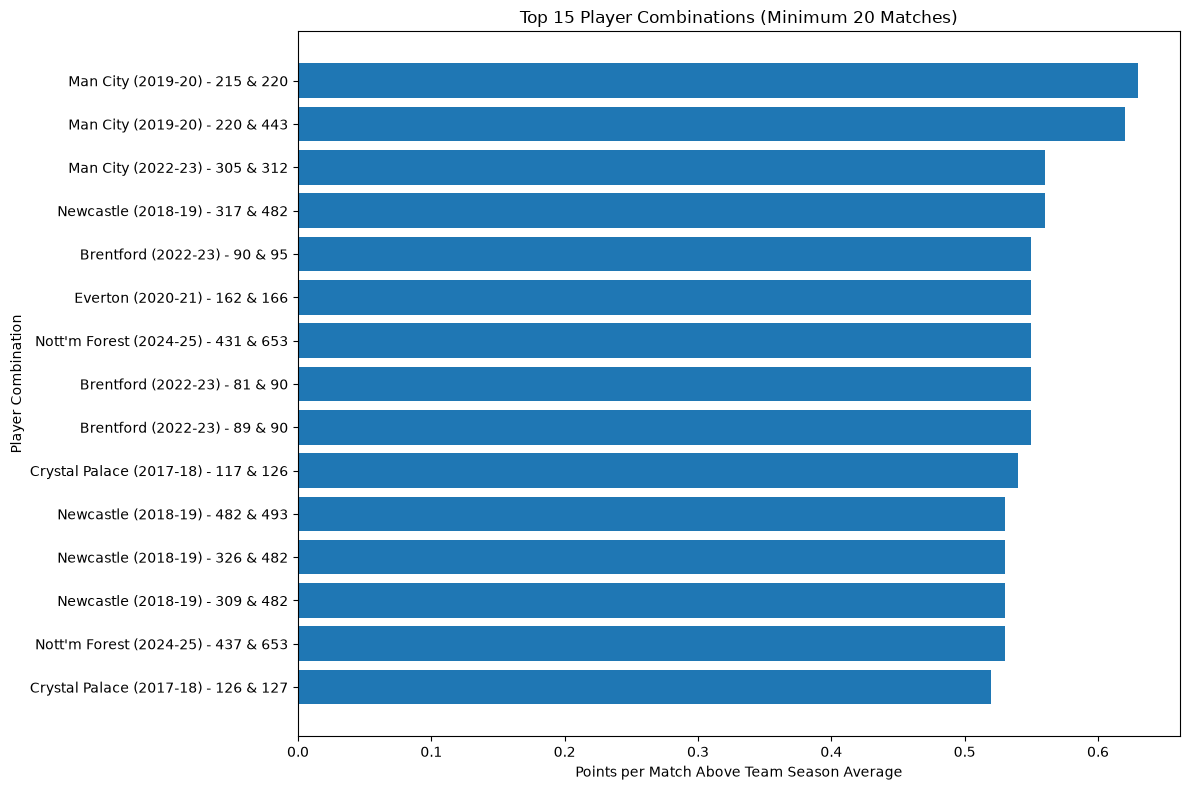

In [33]:
import matplotlib.pyplot as plt

plot_data = top_20_pairs.head(15).copy()

plot_data["pair_label"] = (
    plot_data["team"] + " (" +
    plot_data["season"] + ") - " +
    plot_data["player_1"].astype(str) + " & " +
    plot_data["player_2"].astype(str)
)

plot_data = plot_data.sort_values("points_difference")

plt.figure(figsize=(12, 8))

plt.barh(
    plot_data["pair_label"],
    plot_data["points_difference"]
)

plt.xlabel("Points per Match Above Team Season Average")
plt.ylabel("Player Combination")
plt.title("Top 15 Player Combinations (Minimum 20 Matches)")

plt.tight_layout()
plt.show()

In [34]:
from pathlib import Path

Path("cleaned_data").mkdir(exist_ok=True)

pair_stats.to_csv(
    "cleaned_data/player_pair_statistics_v1.csv",
    index=False
)

pair_stats.to_excel(
    "cleaned_data/player_pair_statistics_v1.xlsx",
    index=False
)

pair_comparison.to_csv(
    "cleaned_data/player_pair_comparison_v1.csv",
    index=False
)

pair_comparison.to_excel(
    "cleaned_data/player_pair_comparison_v1.xlsx",
    index=False
)

team_baselines.to_csv(
    "cleaned_data/team_season_baselines_v1.csv",
    index=False
)

team_baselines.to_excel(
    "cleaned_data/team_season_baselines_v1.xlsx",
    index=False
)

print("Player pair analysis datasets saved successfully.")

Player pair analysis datasets saved successfully.


In [35]:
top_performing_pairs.to_csv(
    "cleaned_data/top_performing_pairs_v1.csv",
    index=False
)

top_performing_pairs.to_excel(
    "cleaned_data/top_performing_pairs_v1.xlsx",
    index=False
)

print("Top-performing player combinations saved successfully.")
print("Records exported:", len(top_performing_pairs))

Top-performing player combinations saved successfully.
Records exported: 30880


Day 2 start-- confirm everything loaded okay

In [36]:
print("Player appearances:", players.shape)
print("Pair appearances:", all_pairs_df.shape)
print("Pair statistics:", pair_stats.shape)
print("Pair comparisons:", pair_comparison.shape)
print("Team baselines:", team_baselines.shape)

Player appearances: (108681, 24)
Pair appearances: (726748, 6)
Pair statistics: (63320, 10)
Pair comparisons: (30880, 14)
Team baselines: (200, 8)


Validate player minutes

In [37]:
print("Total player records:", len(players))

print("Zero minutes:",
      (players["minutes"] == 0).sum())

print("More than zero minutes:",
      (players["minutes"] > 0).sum())

print("Missing minutes:",
      players["minutes"].isna().sum())

Total player records: 108681
Zero minutes: 0
More than zero minutes: 108681
Missing minutes: 0


Validate player names and id's

In [38]:
print(players[[
    "season",
    "team_name_corrected",
    "element",
    "name"
]].head(10))

print("\nMissing player names:",
      players["name"].isna().sum())

print("\nUnique player IDs:",
      players["element"].nunique())

    season team_name_corrected  element              name
0  2016-17             Everton      142      Aaron_Lennon
1  2016-17             Arsenal       16      Aaron_Ramsey
2  2016-17                Hull      163    Abel_Hernández
3  2016-17                Hull      164    Adama_Diomande
4  2016-17       Middlesbrough      283      Adam_Clayton
5  2016-17       Middlesbrough      286      Adam_Forshaw
6  2016-17           Liverpool      205      Adam_Lallana
7  2016-17         Bournemouth       34        Adam_Smith
8  2016-17             Watford      415  Adlène_Guédioura
9  2016-17          Sunderland      261     Adnan_Januzaj

Missing player names: 0

Unique player IDs: 813


In [39]:
player_id_check = (
    players.groupby(["season", "element"])["name"]
    .nunique()
    .reset_index(name="name_count")
)

conflicting_ids = player_id_check[
    player_id_check["name_count"] > 1
]

print("Unique season/player ID combinations:",
      len(player_id_check))

print("IDs associated with multiple names:",
      len(conflicting_ids))

display(conflicting_ids.head(10))

Unique season/player ID combinations: 5343
IDs associated with multiple names: 4


,season,element,name_count
1481,2018-19,515,2
3765,2023-24,120,2
4119,2023-24,620,2
4165,2023-24,687,2


Check player name and id conflict

In [40]:
conflict_details = players.merge(
    conflicting_ids[["season", "element"]],
    on=["season", "element"],
    how="inner"
)

conflict_summary = (
    conflict_details.groupby(
        ["season", "element", "team_name_corrected", "name"]
    )
    .agg(
        appearances=("fixture", "nunique"),
        total_minutes=("minutes", "sum")
    )
    .reset_index()
    .sort_values(["season", "element", "name"])
)

display(conflict_summary)

,season,element,team_name_corrected,name,appearances,total_minutes
0,2018-19,515,Leicester,Caglar_Söyüncü_515,5,281
1,2018-19,515,Leicester,Çaglar_Söyüncü_515,1,90
2,2023-24,120,Brentford,Yegor Yarmoliuk,24,630
3,2023-24,120,Brentford,Yegor Yarmolyuk,3,40
4,2023-24,620,Brentford,Michael Olakigbe,7,43
5,2023-24,620,Brentford,Michale Olakigbe,1,8
6,2023-24,687,Chelsea,Djordje Petrovic,5,366
7,2023-24,687,Chelsea,Đorđe Petrović,18,1620


Standardize 4 player names

In [41]:
player_lookup = players[
    ["season", "element", "name"]
].drop_duplicates().copy()

name_corrections = {
    ("2018-19", 515): "Çağlar Söyüncü",
    ("2023-24", 120): "Yegor Yarmolyuk",
    ("2023-24", 620): "Michael Olakigbe",
    ("2023-24", 687): "Đorđe Petrović"
}

for (season, element), corrected_name in name_corrections.items():
    mask = (
        (player_lookup["season"] == season) &
        (player_lookup["element"] == element)
    )

    player_lookup.loc[mask, "name"] = corrected_name

player_lookup = player_lookup.drop_duplicates(
    subset=["season", "element"]
)

print("Player lookup records:", len(player_lookup))

print("Duplicate season/player IDs:",
      player_lookup.duplicated(
          subset=["season", "element"]
      ).sum())

Player lookup records: 5343
Duplicate season/player IDs: 0


Add player names to comparisons

In [42]:
# Create a separate dataset with player names
pair_comparison_named = pair_comparison.copy()

# Add the first player's name
pair_comparison_named = pair_comparison_named.merge(
    player_lookup.rename(
        columns={
            "element": "player_1",
            "name": "player_1_name"
        }
    ),
    on=["season", "player_1"],
    how="left",
    validate="many_to_one"
)

# Add the second player's name
pair_comparison_named = pair_comparison_named.merge(
    player_lookup.rename(
        columns={
            "element": "player_2",
            "name": "player_2_name"
        }
    ),
    on=["season", "player_2"],
    how="left",
    validate="many_to_one"
)

print("Original records:", len(pair_comparison))
print("Named records:", len(pair_comparison_named))

print("Missing player 1 names:",
      pair_comparison_named["player_1_name"].isna().sum())

print("Missing player 2 names:",
      pair_comparison_named["player_2_name"].isna().sum())

Original records: 30880
Named records: 30880
Missing player 1 names: 0
Missing player 2 names: 0


Top performing with player names

In [43]:
top_pairs_named = (
    pair_comparison_named
    .sort_values(
        by=["points_difference", "matches_together"],
        ascending=[False, False]
    )
)

display(
    top_pairs_named[
        [
            "season",
            "team",
            "player_1_name",
            "player_2_name",
            "matches_together",
            "wins",
            "draws",
            "losses",
            "points_per_match",
            "team_points_per_match",
            "points_difference"
        ]
    ].head(15)
)

,season,team,player_1_name,player_2_name,matches_together,wins,draws,losses,points_per_match,team_points_per_match,points_difference
27115,2024-25,West Ham,Aaron Cresswell,Jean-Clair Todibo,12,9,1,2,2.33,1.13,1.20
20893,2023-24,Aston Villa,Jacob Ramsey,Pau Torres,10,9,1,0,2.80,1.79,1.01
24661,2024-25,Brighton,Simon Adingra,Adam Webster,10,8,2,0,2.60,1.61,0.99
16226,2021-22,Newcastle,Jonjo Shelvey,Bruno Guimarães Rodriguez Moura,11,8,1,2,2.27,1.29,0.98
11511,2020-21,Arsenal,Kieran Tierney,Emile Smith Rowe,12,10,1,1,2.58,1.61,0.97
11537,2020-21,Arsenal,Emile Smith Rowe,Mohamed Naser El Sayed Elneny,12,10,1,1,2.58,1.61,0.97
14755,2021-22,Brighton,Adam Webster,Enock Mwepu,10,7,2,1,2.30,1.34,0.96
27114,2024-25,West Ham,Aaron Cresswell,Guido Rodríguez,12,8,1,3,2.08,1.13,0.95
16204,2021-22,Newcastle,Chris Wood,Jonjo Shelvey,13,9,2,2,2.23,1.29,0.94
3533,2017-18,Crystal Palace,James_Tomkins,Mamadou_Sakho,11,6,5,0,2.09,1.16,0.93


Save files

In [44]:
from pathlib import Path

Path("cleaned_data").mkdir(exist_ok=True)

pair_comparison_named.to_csv(
    "cleaned_data/player_pair_comparison_named_v2.csv",
    index=False,
    encoding="utf-8-sig"
)

pair_comparison_named.to_excel(
    "cleaned_data/player_pair_comparison_named_v2.xlsx",
    index=False
)

top_pairs_named.to_csv(
    "cleaned_data/top_performing_pairs_named_v2.csv",
    index=False,
    encoding="utf-8-sig"
)

top_pairs_named.to_excel(
    "cleaned_data/top_performing_pairs_named_v2.xlsx",
    index=False
)

print("Named player-pair datasets saved successfully.")

Named player-pair datasets saved successfully.


Confirm data-- model prep

In [45]:
print("Team-match dataset shape:", team_matches.shape)

print("\nColumns:")
print(team_matches.columns.tolist())

print("\nSample records:")
display(team_matches.head(10))

print("\nMatch outcomes:")
print(team_matches["result"].value_counts())

Team-match dataset shape: (7600, 4)

Columns:
['season', 'fixture', 'team_name_corrected', 'result']

Sample records:


,season,fixture,team_name_corrected,result
0,2016-17,3,Everton,D
1,2016-17,8,Arsenal,L
2,2016-17,4,Hull,W
4,2016-17,6,Middlesbrough,D
6,2016-17,8,Liverpool,W
7,2016-17,9,Bournemouth,L
8,2016-17,7,Watford,D
9,2016-17,5,Sunderland,L
10,2016-17,10,West Ham,L
12,2016-17,4,Leicester,L



Match outcomes:
result
L    2917
W    2917
D    1766
Name: count, dtype: int64


Chronological match order

In [46]:
print("Kickoff time data type:")
print(players["kickoff_time"].dtype)

print("\nMissing kickoff times:")
print(players["kickoff_time"].isna().sum())

print("\nSample kickoff times:")
display(
    players[
        ["season", "fixture", "team_name_corrected", "kickoff_time"]
    ].head(10)
)

print("\nUnique kickoff times per season/fixture:")
kickoff_check = (
    players.groupby(["season", "fixture"])["kickoff_time"]
    .nunique()
)

print("Fixtures with multiple kickoff times:",
      (kickoff_check > 1).sum())

Kickoff time data type:
str

Missing kickoff times:
0

Sample kickoff times:


,season,fixture,team_name_corrected,kickoff_time
0,2016-17,3,Everton,2016-08-13T14:00:00Z
1,2016-17,8,Arsenal,2016-08-14T15:00:00Z
2,2016-17,4,Hull,2016-08-13T11:30:00Z
3,2016-17,4,Hull,2016-08-13T11:30:00Z
4,2016-17,6,Middlesbrough,2016-08-13T14:00:00Z
5,2016-17,6,Middlesbrough,2016-08-13T14:00:00Z
6,2016-17,8,Liverpool,2016-08-14T15:00:00Z
7,2016-17,9,Bournemouth,2016-08-14T12:30:00Z
8,2016-17,7,Watford,2016-08-13T14:00:00Z
9,2016-17,5,Sunderland,2016-08-13T16:30:00Z



Unique kickoff times per season/fixture:
Fixtures with multiple kickoff times: 0


Add kick-off times to match dataset

In [47]:
# Extract one kickoff time per fixture
match_dates = (
    players[
        ["season", "fixture", "kickoff_time"]
    ]
    .drop_duplicates()
    .copy()
)

# Convert strings to datetime values
match_dates["kickoff_time"] = pd.to_datetime(
    match_dates["kickoff_time"],
    utc=True
)

# Merge kickoff times into team-match records
team_matches_dated = team_matches.merge(
    match_dates,
    on=["season", "fixture"],
    how="left",
    validate="many_to_one"
)

# Arrange matches chronologically
team_matches_dated = (
    team_matches_dated
    .sort_values(
        ["season", "kickoff_time", "fixture", "team_name_corrected"]
    )
    .reset_index(drop=True)
)

print("Original records:", len(team_matches))
print("Dated records:", len(team_matches_dated))
print("Missing kickoff times:",
      team_matches_dated["kickoff_time"].isna().sum())

display(team_matches_dated.head(10))

Original records: 7600
Dated records: 7600
Missing kickoff times: 0


,season,fixture,team_name_corrected,result,kickoff_time
0,2016-17,4,Hull,W,2016-08-13 11:30:00+00:00
1,2016-17,4,Leicester,L,2016-08-13 11:30:00+00:00
2,2016-17,1,Burnley,L,2016-08-13 14:00:00+00:00
3,2016-17,1,Swansea,W,2016-08-13 14:00:00+00:00
4,2016-17,2,Crystal Palace,L,2016-08-13 14:00:00+00:00
5,2016-17,2,West Brom,W,2016-08-13 14:00:00+00:00
6,2016-17,3,Everton,D,2016-08-13 14:00:00+00:00
7,2016-17,3,Spurs,D,2016-08-13 14:00:00+00:00
8,2016-17,6,Middlesbrough,D,2016-08-13 14:00:00+00:00
9,2016-17,6,Stoke,D,2016-08-13 14:00:00+00:00


Create historical team performace features

In [48]:
# Create a working copy
model_data = team_matches_dated.copy()

# Convert match results to league points
points_map = {"W": 3, "D": 1, "L": 0}

model_data["match_points"] = model_data["result"].map(points_map)

# Sort each team's matches chronologically
model_data = model_data.sort_values(
    ["team_name_corrected", "kickoff_time", "fixture"]
).reset_index(drop=True)

# Calculate points per match over the previous 5 matches
model_data["previous_5_ppm"] = (
    model_data
    .groupby("team_name_corrected")["match_points"]
    .transform(
        lambda x: x.shift(1).rolling(
            window=5,
            min_periods=1
        ).mean()
    )
)

display(
    model_data[
        [
            "season",
            "team_name_corrected",
            "kickoff_time",
            "result",
            "match_points",
            "previous_5_ppm"
        ]
    ].head(15)
)

,season,team_name_corrected,kickoff_time,result,match_points,previous_5_ppm
0,2016-17,Arsenal,2016-08-14 15:00:00+00:00,L,0,NaN
1,2016-17,Arsenal,2016-08-20 16:30:00+00:00,D,1,0.000000
2,2016-17,Arsenal,2016-08-27 14:00:00+00:00,W,3,0.500000
3,2016-17,Arsenal,2016-09-10 14:00:00+00:00,W,3,1.333333
4,2016-17,Arsenal,2016-09-17 14:00:00+00:00,W,3,1.750000
5,2016-17,Arsenal,2016-09-24 16:30:00+00:00,W,3,2.000000
6,2016-17,Arsenal,2016-10-02 15:30:00+00:00,W,3,2.600000
7,2016-17,Arsenal,2016-10-15 14:00:00+00:00,W,3,3.000000
8,2016-17,Arsenal,2016-10-22 14:00:00+00:00,D,1,3.000000
9,2016-17,Arsenal,2016-10-29 11:30:00+00:00,W,3,2.600000


Validate historical feature

In [49]:
print("Total records:", len(model_data))

print("Missing historical averages:",
      model_data["previous_5_ppm"].isna().sum())

print("Minimum historical PPM:",
      model_data["previous_5_ppm"].min())

print("Maximum historical PPM:",
      model_data["previous_5_ppm"].max())

print("\nMatch points distribution:")
print(model_data["match_points"].value_counts().sort_index())

print("\nHistorical PPM summary:")
display(model_data["previous_5_ppm"].describe())

Total records: 7600
Missing historical averages: 34
Minimum historical PPM: 0.0
Maximum historical PPM: 3.0

Match points distribution:
match_points
0    2917
1    1766
3    2917
Name: count, dtype: int64

Historical PPM summary:


count    7566.000000
mean        1.387160
std         0.711505
min         0.000000
25%         0.800000
50%         1.400000
75%         1.800000
max         3.000000
Name: previous_5_ppm, dtype: float64

Add recent win percentage

In [50]:
# Identify wins
model_data["is_win"] = (
    model_data["result"] == "W"
).astype(int)

# Calculate win percentage over previous five matches
model_data["previous_5_win_pct"] = (
    model_data
    .groupby("team_name_corrected")["is_win"]
    .transform(
        lambda x: x.shift(1).rolling(
            window=5,
            min_periods=1
        ).mean()
    )
)

display(
    model_data[
        [
            "season",
            "team_name_corrected",
            "result",
            "previous_5_ppm",
            "previous_5_win_pct"
        ]
    ].head(15)
)

,season,team_name_corrected,result,previous_5_ppm,previous_5_win_pct
0,2016-17,Arsenal,L,NaN,NaN
1,2016-17,Arsenal,D,0.000000,0.000000
2,2016-17,Arsenal,W,0.500000,0.000000
3,2016-17,Arsenal,W,1.333333,0.333333
4,2016-17,Arsenal,W,1.750000,0.500000
5,2016-17,Arsenal,W,2.000000,0.600000
6,2016-17,Arsenal,W,2.600000,0.800000
7,2016-17,Arsenal,W,3.000000,1.000000
8,2016-17,Arsenal,D,3.000000,1.000000
9,2016-17,Arsenal,W,2.600000,0.800000


Add hone and away info

In [51]:
home_check = (
    players.groupby(
        ["season", "fixture", "team_name_corrected"]
    )["was_home"]
    .nunique()
)

print("Team-matches with conflicting home/away values:",
      (home_check > 1).sum())

print("\nHome/away distribution:")
print(
    players[
        ["season", "fixture", "team_name_corrected", "was_home"]
    ]
    .drop_duplicates()
    ["was_home"]
    .value_counts()
)

print("\nSample records:")
display(
    players[
        ["season", "fixture", "team_name_corrected", "was_home"]
    ].drop_duplicates().head(10)
)

Team-matches with conflicting home/away values: 0

Home/away distribution:
was_home
True     3800
False    3800
Name: count, dtype: int64

Sample records:


,season,fixture,team_name_corrected,was_home
0,2016-17,3,Everton,True
1,2016-17,8,Arsenal,True
2,2016-17,4,Hull,True
4,2016-17,6,Middlesbrough,True
6,2016-17,8,Liverpool,False
7,2016-17,9,Bournemouth,True
8,2016-17,7,Watford,False
9,2016-17,5,Sunderland,False
10,2016-17,10,West Ham,False
12,2016-17,4,Leicester,False


Add home/away info to model

In [52]:
# Create one home/away record per team-match
home_away = (
    players[
        ["season", "fixture", "team_name_corrected", "was_home"]
    ]
    .drop_duplicates()
    .copy()
)

# Merge home/away information into model_data
model_data = model_data.merge(
    home_away,
    on=["season", "fixture", "team_name_corrected"],
    how="left",
    validate="one_to_one"
)

# Validate the merge
print("Total records:", len(model_data))

print("Missing home/away values:",
      model_data["was_home"].isna().sum())

print("\nHome/away distribution:")
print(model_data["was_home"].value_counts())

display(
    model_data[
        [
            "season",
            "team_name_corrected",
            "result",
            "previous_5_ppm",
            "previous_5_win_pct",
            "was_home"
        ]
    ].head(10)
)

Total records: 7600
Missing home/away values: 0

Home/away distribution:
was_home
True     3800
False    3800
Name: count, dtype: int64


,season,team_name_corrected,result,previous_5_ppm,previous_5_win_pct,was_home
0,2016-17,Arsenal,L,NaN,NaN,True
1,2016-17,Arsenal,D,0.000000,0.000000,False
2,2016-17,Arsenal,W,0.500000,0.000000,False
3,2016-17,Arsenal,W,1.333333,0.333333,True
4,2016-17,Arsenal,W,1.750000,0.500000,False
5,2016-17,Arsenal,W,2.000000,0.600000,True
6,2016-17,Arsenal,W,2.600000,0.800000,False
7,2016-17,Arsenal,W,3.000000,1.000000,True
8,2016-17,Arsenal,D,3.000000,1.000000,True
9,2016-17,Arsenal,W,2.600000,0.800000,False


Identify team opponent

In [53]:
# Create a lookup containing each team's opponent
opponents = model_data[
    ["season", "fixture", "team_name_corrected"]
].copy()

opponents = opponents.rename(
    columns={"team_name_corrected": "opponent"}
)

# Match each team to the other team in the fixture
model_with_opponents = model_data.merge(
    opponents,
    on=["season", "fixture"],
    how="left"
)

# Remove records where a team matches itself
model_with_opponents = model_with_opponents[
    model_with_opponents["team_name_corrected"]
    != model_with_opponents["opponent"]
].copy()

print("Records after opponent merge:",
      len(model_with_opponents))

print("Missing opponents:",
      model_with_opponents["opponent"].isna().sum())

display(
    model_with_opponents[
        [
            "season",
            "fixture",
            "team_name_corrected",
            "opponent",
            "was_home",
            "result"
        ]
    ].head(10)
)

Records after opponent merge: 7600
Missing opponents: 0


,season,fixture,team_name_corrected,opponent,was_home,result
1,2016-17,8,Arsenal,Liverpool,True,L
3,2016-17,13,Arsenal,Leicester,False,D
5,2016-17,28,Arsenal,Watford,False,W
7,2016-17,31,Arsenal,Southampton,True,W
9,2016-17,43,Arsenal,Hull,False,W
11,2016-17,51,Arsenal,Chelsea,True,W
13,2016-17,61,Arsenal,Burnley,False,W
15,2016-17,71,Arsenal,Swansea,True,W
17,2016-17,81,Arsenal,Middlesbrough,True,D
19,2016-17,97,Arsenal,Sunderland,False,W


Add opponent historical performance

In [54]:
# Create a lookup containing opponent performance
opponent_stats = model_data[
    [
        "season",
        "fixture",
        "team_name_corrected",
        "previous_5_ppm",
        "previous_5_win_pct"
    ]
].copy()

# Rename columns to distinguish opponent statistics
opponent_stats = opponent_stats.rename(
    columns={
        "team_name_corrected": "opponent",
        "previous_5_ppm": "opponent_previous_5_ppm",
        "previous_5_win_pct": "opponent_previous_5_win_pct"
    }
)

# Merge opponent performance into our dataset
model_with_opponents = model_with_opponents.merge(
    opponent_stats,
    on=["season", "fixture", "opponent"],
    how="left",
    validate="one_to_one"
)

print("Total records:", len(model_with_opponents))

print("Missing opponent historical PPM:",
      model_with_opponents["opponent_previous_5_ppm"].isna().sum())

display(
    model_with_opponents[
        [
            "season",
            "team_name_corrected",
            "opponent",
            "previous_5_ppm",
            "opponent_previous_5_ppm",
            "was_home",
            "result"
        ]
    ].head(12)
)

Total records: 7600
Missing opponent historical PPM: 34


,season,team_name_corrected,opponent,previous_5_ppm,opponent_previous_5_ppm,was_home,result
0,2016-17,Arsenal,Liverpool,NaN,NaN,True,L
1,2016-17,Arsenal,Leicester,0.000000,0.000000,False,D
2,2016-17,Arsenal,Watford,0.500000,0.500000,False,W
3,2016-17,Arsenal,Southampton,1.333333,0.666667,True,W
4,2016-17,Arsenal,Hull,1.750000,1.750000,False,W
5,2016-17,Arsenal,Chelsea,2.000000,2.000000,True,W
6,2016-17,Arsenal,Burnley,2.600000,1.400000,False,W
7,2016-17,Arsenal,Swansea,3.000000,0.200000,True,W
8,2016-17,Arsenal,Middlesbrough,3.000000,0.200000,True,D
9,2016-17,Arsenal,Sunderland,2.600000,0.200000,False,W


Calculate performance difference

In [55]:
model_with_opponents["ppm_difference"] = (
    model_with_opponents["previous_5_ppm"]
    - model_with_opponents["opponent_previous_5_ppm"]
)

model_with_opponents["win_pct_difference"] = (
    model_with_opponents["previous_5_win_pct"]
    - model_with_opponents["opponent_previous_5_win_pct"]
)

display(
    model_with_opponents[
        [
            "season",
            "team_name_corrected",
            "opponent",
            "previous_5_ppm",
            "opponent_previous_5_ppm",
            "ppm_difference",
            "win_pct_difference",
            "was_home",
            "result"
        ]
    ].head(12)
)

,season,team_name_corrected,opponent,previous_5_ppm,opponent_previous_5_ppm,ppm_difference,win_pct_difference,was_home,result
0,2016-17,Arsenal,Liverpool,NaN,NaN,NaN,NaN,True,L
1,2016-17,Arsenal,Leicester,0.000000,0.000000,0.000000,0.000000,False,D
2,2016-17,Arsenal,Watford,0.500000,0.500000,0.000000,0.000000,False,W
3,2016-17,Arsenal,Southampton,1.333333,0.666667,0.666667,0.333333,True,W
4,2016-17,Arsenal,Hull,1.750000,1.750000,0.000000,0.000000,False,W
5,2016-17,Arsenal,Chelsea,2.000000,2.000000,0.000000,0.000000,True,W
6,2016-17,Arsenal,Burnley,2.600000,1.400000,1.200000,0.400000,False,W
7,2016-17,Arsenal,Swansea,3.000000,0.200000,2.800000,1.000000,True,W
8,2016-17,Arsenal,Middlesbrough,3.000000,0.200000,2.800000,1.000000,True,D
9,2016-17,Arsenal,Sunderland,2.600000,0.200000,2.400000,0.800000,False,W


Validate model features

In [56]:
features = [
    "previous_5_ppm",
    "previous_5_win_pct",
    "opponent_previous_5_ppm",
    "opponent_previous_5_win_pct",
    "ppm_difference",
    "win_pct_difference"
]

print("Total records:", len(model_with_opponents))

print("\nMissing values by feature:")
print(model_with_opponents[features].isna().sum())

print("\nFeature summary:")
display(model_with_opponents[features].describe())

print("\nRecords with complete historical features:")
print(model_with_opponents[features].notna().all(axis=1).sum())

Total records: 7600

Missing values by feature:
previous_5_ppm                 34
previous_5_win_pct             34
opponent_previous_5_ppm        34
opponent_previous_5_win_pct    34
ppm_difference                 48
win_pct_difference             48
dtype: int64

Feature summary:


,previous_5_ppm,previous_5_win_pct,opponent_previous_5_ppm,opponent_previous_5_win_pct,ppm_difference,win_pct_difference
count,7566.000000,7566.000000,7566.000000,7566.000000,7.552000e+03,7552.000000
mean,1.387160,0.385104,1.387160,0.385104,-1.505387e-17,0.000000
std,0.711505,0.254926,0.711505,0.254926,1.005768e+00,0.359835
min,0.000000,0.000000,0.000000,0.000000,-3.000000e+00,-1.000000
25%,0.800000,0.200000,0.800000,0.200000,-6.000000e-01,-0.200000
50%,1.400000,0.400000,1.400000,0.400000,0.000000e+00,0.000000
75%,1.800000,0.600000,1.800000,0.600000,6.000000e-01,0.200000
max,3.000000,1.000000,3.000000,1.000000,3.000000e+00,1.000000



Records with complete historical features:
7552


Prepare modeling dataset

In [57]:
# Create a separate dataset for machine learning
model_ready = model_with_opponents.dropna(
    subset=features
).copy()

# Sort chronologically
model_ready = model_ready.sort_values(
    ["kickoff_time", "season", "fixture", "team_name_corrected"]
).reset_index(drop=True)

print("Original records:", len(model_with_opponents))
print("Model-ready records:", len(model_ready))
print("Removed records:", len(model_with_opponents) - len(model_ready))

print("\nResult distribution:")
print(model_ready["result"].value_counts())

display(model_ready.head(10))

Original records: 7600
Model-ready records: 7552
Removed records: 48

Result distribution:
result
W    2898
L    2898
D    1756
Name: count, dtype: int64


,season,fixture,team_name_corrected,result,kickoff_time,match_points,previous_5_ppm,is_win,previous_5_win_pct,was_home,opponent,opponent_previous_5_ppm,opponent_previous_5_win_pct,ppm_difference,win_pct_difference
0,2016-17,11,Man Utd,W,2016-08-19 19:00:00+00:00,3,3.0,1,1.0,True,Southampton,1.0,0.0,2.0,1.0
1,2016-17,11,Southampton,L,2016-08-19 19:00:00+00:00,0,1.0,0,0.0,False,Man Utd,3.0,1.0,-2.0,-1.0
2,2016-17,14,Man City,W,2016-08-20 11:30:00+00:00,3,3.0,1,1.0,False,Stoke,1.0,0.0,2.0,1.0
3,2016-17,14,Stoke,L,2016-08-20 11:30:00+00:00,0,1.0,0,0.0,True,Man City,3.0,1.0,-2.0,-1.0
4,2016-17,12,Burnley,W,2016-08-20 14:00:00+00:00,3,0.0,1,0.0,True,Liverpool,3.0,1.0,-3.0,-1.0
5,2016-17,12,Liverpool,L,2016-08-20 14:00:00+00:00,0,3.0,0,1.0,False,Burnley,0.0,0.0,3.0,1.0
6,2016-17,15,Hull,W,2016-08-20 14:00:00+00:00,3,3.0,1,1.0,False,Swansea,3.0,1.0,0.0,0.0
7,2016-17,15,Swansea,L,2016-08-20 14:00:00+00:00,0,3.0,0,1.0,True,Hull,3.0,1.0,0.0,0.0
8,2016-17,16,Crystal Palace,L,2016-08-20 14:00:00+00:00,0,0.0,0,0.0,False,Spurs,1.0,0.0,-1.0,0.0
9,2016-17,16,Spurs,W,2016-08-20 14:00:00+00:00,3,1.0,1,0.0,True,Crystal Palace,0.0,0.0,1.0,0.0


Save model ready dataset

In [58]:
from pathlib import Path

# Create output folder if necessary
output_folder = Path("cleaned_data")
output_folder.mkdir(exist_ok=True)

# Save complete modeling dataset
model_with_opponents.to_csv(
    output_folder / "model_features_complete_v1.csv",
    index=False
)

model_with_opponents.to_excel(
    output_folder / "model_features_complete_v1.xlsx",
    index=False
)

# Save model-ready dataset
model_ready.to_csv(
    output_folder / "model_ready_v1.csv",
    index=False
)

model_ready.to_excel(
    output_folder / "model_ready_v1.xlsx",
    index=False
)

print("Modeling datasets saved successfully.")
print("Complete records:", len(model_with_opponents))
print("Model-ready records:", len(model_ready))

ValueError: Excel does not support datetimes with timezones. Please ensure that datetimes are timezone unaware before writing to Excel.

Deal with datetime conflict

In [59]:
# Create copies specifically for Excel export
complete_excel = model_with_opponents.copy()
ready_excel = model_ready.copy()

# Remove timezone information for Excel compatibility
complete_excel["kickoff_time"] = (
    complete_excel["kickoff_time"].dt.tz_localize(None)
)

ready_excel["kickoff_time"] = (
    ready_excel["kickoff_time"].dt.tz_localize(None)
)

# Export Excel versions
complete_excel.to_excel(
    output_folder / "model_features_complete_v1.xlsx",
    index=False
)

ready_excel.to_excel(
    output_folder / "model_ready_v1.xlsx",
    index=False
)

print("Both Excel files saved successfully.")

Both Excel files saved successfully.


In [60]:
model_ready.to_csv(
    output_folder / "model_ready_v1.csv",
    index=False
)

print("Model-ready CSV saved successfully.")

Model-ready CSV saved successfully.


Create training and testing sets

In [61]:
# Define training and testing seasons
train_seasons = [
    "2016-17", "2017-18", "2018-19", "2019-20",
    "2020-21", "2021-22", "2022-23", "2023-24"
]

test_seasons = ["2024-25", "2025-26"]

# Create separate datasets
train_data = model_ready[
    model_ready["season"].isin(train_seasons)
].copy()

test_data = model_ready[
    model_ready["season"].isin(test_seasons)
].copy()

# Verify the split
print("Training records:", len(train_data))
print("Testing records:", len(test_data))

print("\nTraining seasons:")
print(train_data["season"].value_counts().sort_index())

print("\nTesting seasons:")
print(test_data["season"].value_counts().sort_index())

print("\nOverlapping fixtures:",
    len(
        set(zip(train_data["season"], train_data["fixture"]))
        &
        set(zip(test_data["season"], test_data["fixture"]))
    )
)

Training records: 6034
Testing records: 1518

Training seasons:
season
2016-17    740
2017-18    754
2018-19    754
2019-20    754
2020-21    758
2021-22    758
2022-23    758
2023-24    758
Name: count, dtype: int64

Testing seasons:
season
2024-25    758
2025-26    760
Name: count, dtype: int64

Overlapping fixtures: 0


Define predictors and target

In [62]:
# Features available before the match
feature_columns = [
    "ppm_difference",
    "win_pct_difference",
    "was_home"
]

# Training features and target
X_train = train_data[feature_columns].copy()
y_train = train_data["result"].copy()

# Testing features and target
X_test = test_data[feature_columns].copy()
y_test = test_data["result"].copy()

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining targets:")
print(y_train.value_counts())

print("\nTesting targets:")
print(y_test.value_counts())

display(X_train.head(10))

Training features: (6034, 3)
Testing features: (1518, 3)

Training targets:
result
W    2336
L    2336
D    1362
Name: count, dtype: int64

Testing targets:
result
L    562
W    562
D    394
Name: count, dtype: int64


,ppm_difference,win_pct_difference,was_home
0,2.0,1.0,True
1,-2.0,-1.0,False
2,2.0,1.0,False
3,-2.0,-1.0,True
4,-3.0,-1.0,True
5,3.0,1.0,False
6,0.0,0.0,False
7,0.0,0.0,True
8,-1.0,0.0,False
9,1.0,0.0,True


Train first model

In [64]:
%pip install scikit-learn

  Using cached scipy-1.18.1-cp314-cp314-win_amd64.whl.metadata (61 kB)
  Using cached joblib-1.6.0-py3-none-any.whl.metadata (6.5 kB)
  Using cached cloudpickle-3.1.2-py3-none-any.whl.metadata (7.1 kB)
   ---------------------------------------- 0.0/8.4 MB ? eta -:--:--
   --------------- ------------------------ 3.1/8.4 MB 25.7 MB/s eta 0:00:01
   ---------------------------------------- 8.4/8.4 MB 41.8 MB/s  0:00:00
Using cached joblib-1.6.0-py3-none-any.whl (306 kB)
Using cached cloudpickle-3.1.2-py3-none-any.whl (22 kB)
Using cached scipy-1.18.1-cp314-cp314-win_amd64.whl (37.4 MB)

   ------ --------------------------------- 1/6 [scipy]
   ------ --------------------------------- 1/6 [scipy]
   ------ --------------------------------- 1/6 [scipy]
   ------ --------------------------------- 1/6 [scipy]
   ------ --------------------------------- 1/6 [scipy]
   ------ --------------------------------- 1/6 [scipy]
   ------ --------------------------------- 1/6 [scipy]
   ------ -----


[notice] A new release of pip is available: 25.3 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [65]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

# Create a baseline classification model
baseline_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=1000)
)

# Train using historical seasons only
baseline_model.fit(X_train, y_train)

print("Baseline model trained successfully.")
print("Classes:", baseline_model.classes_)
print("Training accuracy:", round(
    baseline_model.score(X_train, y_train), 4
))

Baseline model trained successfully.
Classes: ['D' 'L' 'W']
Training accuracy: 0.5121


Evaluate test model with test seasons

In [66]:
from sklearn.metrics import accuracy_score, classification_report

# Predict outcomes for the testing seasons
y_pred = baseline_model.predict(X_test)

# Calculate testing accuracy
test_accuracy = accuracy_score(y_test, y_pred)

print("Training accuracy:",
      round(baseline_model.score(X_train, y_train), 4))

print("Testing accuracy:", round(test_accuracy, 4))

print("\nClassification report:")
print(classification_report(y_test, y_pred, zero_division=0))

Training accuracy: 0.5121
Testing accuracy: 0.4625

Classification report:
              precision    recall  f1-score   support

           D       0.00      0.00      0.00       394
           L       0.46      0.62      0.53       562
           W       0.46      0.62      0.53       562

    accuracy                           0.46      1518
   macro avg       0.31      0.42      0.35      1518
weighted avg       0.34      0.46      0.39      1518



Create Viz

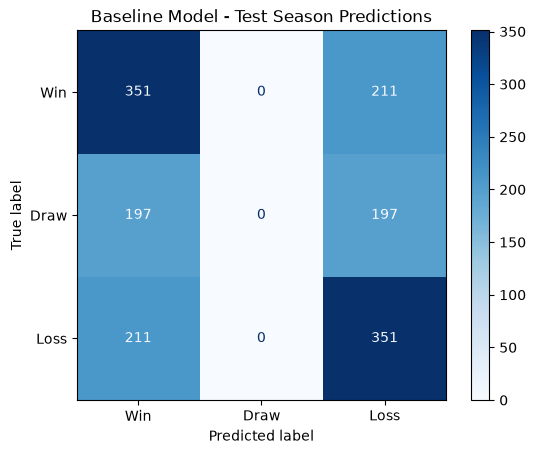

In [67]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    labels=["W", "D", "L"],
    display_labels=["Win", "Draw", "Loss"],
    cmap="Blues",
    values_format="d"
)

plt.title("Baseline Model - Test Season Predictions")
plt.show()

In [68]:
# Select one match from the testing dataset
sample = X_test.iloc[[0]]

# Predict the result
prediction = baseline_model.predict(sample)

# Calculate probabilities for each outcome
probabilities = baseline_model.predict_proba(sample)

print("Predicted result:", prediction[0])
print("Actual result:", y_test.iloc[0])

print("\nPrediction probabilities:")
for outcome, probability in zip(
    baseline_model.classes_,
    probabilities[0]
):
    print(outcome, ":", round(probability * 100, 2), "%")

Predicted result: L
Actual result: L

Prediction probabilities:
D : 22.85 %
L : 51.44 %
W : 25.71 %


Model 2 -- Prepare player pair history

In [69]:
print("Pair records:", len(all_pairs_df))

print("\nColumns:")
print(all_pairs_df.columns.tolist())

print("\nSample records:")
display(all_pairs_df.head(10))

print("\nUnique seasons:")
print(sorted(all_pairs_df["season"].unique()))

Pair records: 726748

Columns:
['season', 'fixture', 'team', 'player_1', 'player_2', 'result']

Sample records:


,season,fixture,team,player_1,player_2,result
0,2016-17,1,Burnley,54,55,L
1,2016-17,1,Burnley,54,56,L
2,2016-17,1,Burnley,54,57,L
3,2016-17,1,Burnley,54,58,L
4,2016-17,1,Burnley,54,61,L
5,2016-17,1,Burnley,54,62,L
6,2016-17,1,Burnley,54,63,L
7,2016-17,1,Burnley,54,64,L
8,2016-17,1,Burnley,54,67,L
9,2016-17,1,Burnley,54,68,L



Unique seasons:
['2016-17', '2017-18', '2018-19', '2019-20', '2020-21', '2021-22', '2022-23', '2023-24', '2024-25', '2025-26']


Attach match dates to player pairs

In [72]:
# Create a lookup of match dates
match_dates = team_matches_dated[
    ["season", "fixture", "team_name_corrected", "kickoff_time"]
].rename(
    columns={"team_name_corrected": "team"}
)

# Attach dates to player-pair appearances
pairs_dated = all_pairs_df.merge(
    match_dates,
    on=["season", "fixture", "team"],
    how="left",
    validate="many_to_one"
)

print("Original pair records:", len(all_pairs_df))
print("Dated pair records:", len(pairs_dated))

print("Missing kickoff times:",
      pairs_dated["kickoff_time"].isna().sum())

display(pairs_dated.head(10))

Original pair records: 726748
Dated pair records: 726748
Missing kickoff times: 0


,season,fixture,team,player_1,player_2,result,kickoff_time
0,2016-17,1,Burnley,54,55,L,2016-08-13 14:00:00+00:00
1,2016-17,1,Burnley,54,56,L,2016-08-13 14:00:00+00:00
2,2016-17,1,Burnley,54,57,L,2016-08-13 14:00:00+00:00
3,2016-17,1,Burnley,54,58,L,2016-08-13 14:00:00+00:00
4,2016-17,1,Burnley,54,61,L,2016-08-13 14:00:00+00:00
5,2016-17,1,Burnley,54,62,L,2016-08-13 14:00:00+00:00
6,2016-17,1,Burnley,54,63,L,2016-08-13 14:00:00+00:00
7,2016-17,1,Burnley,54,64,L,2016-08-13 14:00:00+00:00
8,2016-17,1,Burnley,54,67,L,2016-08-13 14:00:00+00:00
9,2016-17,1,Burnley,54,68,L,2016-08-13 14:00:00+00:00


In [71]:
# Create a lookup of match dates
match_dates = team_matches_dated[
    ["season", "fixture", "team_name_corrected", "kickoff_time"]
].rename(
    columns={"team_name_corrected": "team"}
)

Calculate historical player pair performance

In [73]:
# Sort player pairs chronologically
pairs_history = pairs_dated.sort_values(
    ["season", "team", "player_1", "player_2", "kickoff_time", "fixture"]
).copy()

# Convert match results to points
pairs_history["pair_match_points"] = (
    pairs_history["result"].map({"W": 3, "D": 1, "L": 0})
)

# Group each pair within its team and season
pair_groups = pairs_history.groupby(
    ["season", "team", "player_1", "player_2"]
)

# Count previous appearances together
pairs_history["previous_matches_together"] = pair_groups.cumcount()

# Calculate points earned before the current match
pairs_history["previous_pair_points"] = (
    pair_groups["pair_match_points"].cumsum()
    - pairs_history["pair_match_points"]
)

# Historical average points per match
pairs_history["previous_pair_ppm"] = (
    pairs_history["previous_pair_points"]
    / pairs_history["previous_matches_together"].replace(0, float("nan"))
)

display(
    pairs_history[
        [
            "season", "team", "player_1", "player_2",
            "result", "previous_matches_together",
            "previous_pair_ppm"
        ]
    ].head(15)
)

,season,team,player_1,player_2,result,previous_matches_together,previous_pair_ppm
50863,2016-17,Arsenal,1,2,L,0,NaN
50864,2016-17,Arsenal,1,3,L,0,NaN
51227,2016-17,Arsenal,1,3,D,1,0.0
51228,2016-17,Arsenal,1,5,D,0,NaN
50865,2016-17,Arsenal,1,6,L,0,NaN
51229,2016-17,Arsenal,1,6,D,1,0.0
50866,2016-17,Arsenal,1,10,L,0,NaN
51230,2016-17,Arsenal,1,10,D,1,0.0
50867,2016-17,Arsenal,1,12,L,0,NaN
51231,2016-17,Arsenal,1,12,D,1,0.0


Check historical calulations

In [74]:
print("Total pair records:", len(pairs_history))

print(
    "Pairs with no previous appearances:",
    (pairs_history["previous_matches_together"] == 0).sum()
)

print(
    "Historical PPM minimum:",
    pairs_history["previous_pair_ppm"].min()
)

print(
    "Historical PPM maximum:",
    pairs_history["previous_pair_ppm"].max()
)

print(
    "Invalid historical PPM values:",
    (
        (pairs_history["previous_pair_ppm"] < 0) |
        (pairs_history["previous_pair_ppm"] > 3)
    ).sum()
)

Total pair records: 726748
Pairs with no previous appearances: 63320
Historical PPM minimum: 0.0
Historical PPM maximum: 3.0
Invalid historical PPM values: 0


Aggregate pair performance by team and match

In [75]:
# Aggregate historical player-pair performance
# into one record per team-match

pair_match_features = (
    pairs_history.groupby(
        ["season", "fixture", "team"]
    )
    .agg(
        avg_pair_ppm=("previous_pair_ppm", "mean"),
        experienced_pairs=("previous_pair_ppm", "count"),
        total_pairs=("player_1", "count")
    )
    .reset_index()
)

# Calculate proportion of pairs with previous experience
pair_match_features["pair_experience_pct"] = (
    pair_match_features["experienced_pairs"]
    / pair_match_features["total_pairs"]
)

print("Team-match records:", len(pair_match_features))

print(
    "Missing average pair PPM:",
    pair_match_features["avg_pair_ppm"].isna().sum()
)

display(pair_match_features.head(10))

Team-match records: 7600
Missing average pair PPM: 200


,season,fixture,team,avg_pair_ppm,experienced_pairs,total_pairs,pair_experience_pct
0,2016-17,1,Burnley,NaN,0,78,0.0
1,2016-17,1,Swansea,NaN,0,91,0.0
2,2016-17,2,Crystal Palace,NaN,0,91,0.0
3,2016-17,2,West Brom,NaN,0,78,0.0
4,2016-17,3,Everton,NaN,0,91,0.0
5,2016-17,3,Spurs,NaN,0,78,0.0
6,2016-17,4,Hull,NaN,0,55,0.0
7,2016-17,4,Leicester,NaN,0,91,0.0
8,2016-17,5,Man City,NaN,0,91,0.0
9,2016-17,5,Sunderland,NaN,0,91,0.0


Merge pair features into modeling dataset

In [76]:
# Prepare player-pair features for merging
pair_features_lookup = pair_match_features.rename(
    columns={"team": "team_name_corrected"}
)

# Add player-pair features to our existing model dataset
model_2_data = model_ready.merge(
    pair_features_lookup[
        [
            "season",
            "fixture",
            "team_name_corrected",
            "avg_pair_ppm",
            "experienced_pairs",
            "total_pairs",
            "pair_experience_pct"
        ]
    ],
    on=["season", "fixture", "team_name_corrected"],
    how="left",
    validate="one_to_one"
)

print("Original model records:", len(model_ready))
print("Model 2 records:", len(model_2_data))

print("\nMissing pair features:")
print(
    model_2_data[
        ["avg_pair_ppm", "pair_experience_pct"]
    ].isna().sum()
)

display(
    model_2_data[
        [
            "season",
            "team_name_corrected",
            "result",
            "ppm_difference",
            "was_home",
            "avg_pair_ppm",
            "pair_experience_pct"
        ]
    ].head(10)
)

Original model records: 7552
Model 2 records: 7552

Missing pair features:
avg_pair_ppm           152
pair_experience_pct      0
dtype: int64


,season,team_name_corrected,result,ppm_difference,was_home,avg_pair_ppm,pair_experience_pct
0,2016-17,Man Utd,W,2.0,True,3.0,0.725275
1,2016-17,Southampton,L,-2.0,False,1.0,0.604396
2,2016-17,Man City,W,2.0,False,3.0,0.725275
3,2016-17,Stoke,L,-2.0,True,1.0,0.846154
4,2016-17,Burnley,W,-3.0,True,0.0,0.725275
5,2016-17,Liverpool,L,3.0,False,3.0,0.604396
6,2016-17,Hull,W,0.0,False,3.0,0.833333
7,2016-17,Swansea,L,0.0,True,3.0,0.725275
8,2016-17,Crystal Palace,L,-1.0,False,0.0,0.604396
9,2016-17,Spurs,W,1.0,True,1.0,0.725275


Prepare model 2 for training

In [77]:
# Preserve the original dataset
model_2_ready = model_2_data.copy()

# Handle pairs with no previous match history
model_2_ready["avg_pair_ppm"] = (
    model_2_ready["avg_pair_ppm"].fillna(0)
)

# Select features for Model 2
features_2 = [
    "ppm_difference",
    "win_pct_difference",
    "was_home",
    "avg_pair_ppm",
    "pair_experience_pct"
]

# Use the same seasons as Model 1
train_2 = model_2_ready[
    model_2_ready["season"].isin(train_data["season"].unique())
].copy()

test_2 = model_2_ready[
    model_2_ready["season"].isin(test_data["season"].unique())
].copy()

X_train_2 = train_2[features_2]
y_train_2 = train_2["result"]

X_test_2 = test_2[features_2]
y_test_2 = test_2["result"]

print("Model 2 training records:", len(X_train_2))
print("Model 2 testing records:", len(X_test_2))

print("\nMissing training features:")
print(X_train_2.isna().sum())

print("\nMissing testing features:")
print(X_test_2.isna().sum())

Model 2 training records: 6034
Model 2 testing records: 1518

Missing training features:
ppm_difference         0
win_pct_difference     0
was_home               0
avg_pair_ppm           0
pair_experience_pct    0
dtype: int64

Missing testing features:
ppm_difference         0
win_pct_difference     0
was_home               0
avg_pair_ppm           0
pair_experience_pct    0
dtype: int64


Train model 2

In [78]:
# Model 2: Logistic regression with player-pair features

model_2 = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=1000)
)

# Train on historical seasons
model_2.fit(X_train_2, y_train_2)

# Predict results for testing seasons
y_pred_2 = model_2.predict(X_test_2)

# Evaluate performance
model_2_train_accuracy = model_2.score(X_train_2, y_train_2)
model_2_test_accuracy = accuracy_score(y_test_2, y_pred_2)

print("Model 2 trained successfully.")

print("\nModel comparison:")
print("Model 1 testing accuracy:", round(test_accuracy, 4))
print("Model 2 training accuracy:", round(model_2_train_accuracy, 4))
print("Model 2 testing accuracy:", round(model_2_test_accuracy, 4))

print("\nModel 2 classification report:")
print(classification_report(y_test_2, y_pred_2, zero_division=0))

Model 2 trained successfully.

Model comparison:
Model 1 testing accuracy: 0.4625
Model 2 training accuracy: 0.5134
Model 2 testing accuracy: 0.4697

Model 2 classification report:
              precision    recall  f1-score   support

           D       0.00      0.00      0.00       394
           L       0.47      0.65      0.55       562
           W       0.47      0.62      0.53       562

    accuracy                           0.47      1518
   macro avg       0.31      0.42      0.36      1518
weighted avg       0.35      0.47      0.40      1518



Viz to compare models

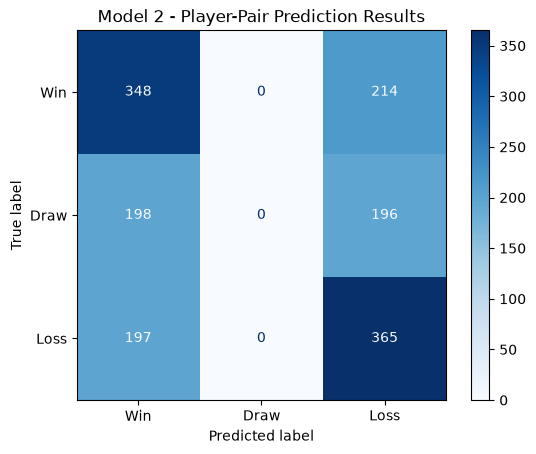

In [79]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

ConfusionMatrixDisplay.from_predictions(
    y_test_2,
    y_pred_2,
    labels=["W", "D", "L"],
    display_labels=["Win", "Draw", "Loss"],
    cmap="Blues",
    values_format="d"
)

plt.title("Model 2 - Player-Pair Prediction Results")
plt.show()